# Parte 4 · La escala también es geometría (4.1 a 4.4)

**Autor:** Gregorio Coronel · Grupo Taiwan

**Declaración de uso de IA:** se utilizó Claude (Anthropic) como herramienta de apoyo para comprender lo que pedía cada inciso del enunciado y como asistencia al escribir y depurar el código. El análisis, la verificación de resultados y su interpretación fueron revisados por el autor.

Esta es la única parte que usa también las variables **crudas**: `cargar_taiwan(..., escalar=False)` da la misma partición 80/20 sin estandarizar. Las desviaciones estándar son las que guardó 0.4 en `resultados/sd_taiwan.csv` y las consultas son las de 2.1 en `resultados/consultas.json`.

In [1]:
import sys, json
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from datos import cargar_taiwan

X_train, X_test, y_train, y_test, _ = cargar_taiwan("../data/taiwan_credit.csv")
Xc_train, Xc_test, _, _, _ = cargar_taiwan("../data/taiwan_credit.csv", escalar=False)
sd = pd.read_csv("../resultados/sd_taiwan.csv", index_col=0)["sd"]
hp = json.load(open("../resultados/hiperparametros.json"))
consultas = json.load(open("../resultados/consultas.json"))
mse = lambda y, p: np.mean((y - p) ** 2)
assert (Xc_train.index == X_train.index).all() and np.allclose(Xc_train.std(ddof=0), sd)

## 4.1 · k-NN con $k = 10$ en tres escalas

Se ajusta el mismo `KNeighborsRegressor(n_neighbors=10)` sobre las variables crudas, las estandarizadas y los componentes principales que explican el 90 % de la varianza. El PCA se ajusta con el entrenamiento estandarizado; como referencia se agrega también el PCA sobre las crudas y el MSE de predecir siempre la tasa de mora del entrenamiento.

In [2]:
pca = PCA(n_components=0.90).fit(X_train)
pca_crudo = PCA(n_components=0.90).fit(Xc_train)
espacios = {
    "crudas": (Xc_train, Xc_test),
    "estandarizadas": (X_train, X_test),
    f"PCA 90 % de las estandarizadas ({pca.n_components_} comp.)": (pca.transform(X_train), pca.transform(X_test)),
    f"PCA 90 % de las crudas ({pca_crudo.n_components_} comp.)": (pca_crudo.transform(Xc_train), pca_crudo.transform(Xc_test)),
}
knn = {nombre: KNeighborsRegressor(n_neighbors=10).fit(a, y_train) for nombre, (a, _) in espacios.items()}
error_knn = pd.Series({nombre: mse(y_test, knn[nombre].predict(b)) for nombre, (_, b) in espacios.items()})
error_knn["(predecir la media)"] = mse(y_test, y_train.mean())
error_knn.to_frame("MSE de prueba").round(4)

,MSE de prueba
crudas,0.1706
estandarizadas,0.1471
PCA 90 % de las estandarizadas (13 comp.),0.1508
PCA 90 % de las crudas (2 comp.),0.1746
(predecir la media),0.1695


In [3]:
# En escala cruda, E||x_i − x_j||² = 2 Σ_v sd_v²: cada variable pesa en la distancia según su varianza
peso = (sd**2 / (sd**2).sum()).sort_values(ascending=False)
grupo = lambda v: "montos" if v.startswith(("LIMIT", "BILL", "PAY_AMT")) else "otras"
print("Parte de la distancia cruda que aportan los montos:", f"{peso.groupby(grupo).sum()['montos']:.6f}")
pd.DataFrame({"sd": sd[peso.index], "parte de la distancia cruda": peso,
              "parte en estandarizadas": 1 / len(sd)}).head(8).style.format({"sd": "{:,.1f}", "parte de la distancia cruda": "{:.4f}", "parte en estandarizadas": "{:.4f}"})

Parte de la distancia cruda que aportan los montos: 1.000000


,sd,parte de la distancia cruda,parte en estandarizadas
LIMIT_BAL,"129,479.7",0.3704,0.0435
BILL_AMT1,"73,525.2",0.1194,0.0435
BILL_AMT2,"70,960.6",0.1112,0.0435
BILL_AMT3,"69,505.3",0.1067,0.0435
BILL_AMT4,"64,153.3",0.0909,0.0435
BILL_AMT5,"60,673.6",0.0813,0.0435
BILL_AMT6,"59,424.7",0.0780,0.0435
PAY_AMT2,"23,436.6",0.0121,0.0435


In [4]:
print(f"Parte de la distancia cruda de PAY_0 a PAY_6: {peso.filter(like='PAY_').drop(peso.filter(like='PAY_AMT').index).sum():.2e}")
print(f"Primer componente del PCA crudo: varianza explicada {pca_crudo.explained_variance_ratio_[0]:.3f}")
pd.Series(pca_crudo.components_[0], index=X_train.columns).abs().sort_values(ascending=False).head(5).round(3)

Parte de la distancia cruda de PAY_0 a PAY_6: 1.79e-10
Primer componente del PCA crudo: varianza explicada 0.610


LIMIT_BAL    0.490
BILL_AMT1    0.389
BILL_AMT2    0.381
BILL_AMT3    0.374
BILL_AMT4    0.346
dtype: float64

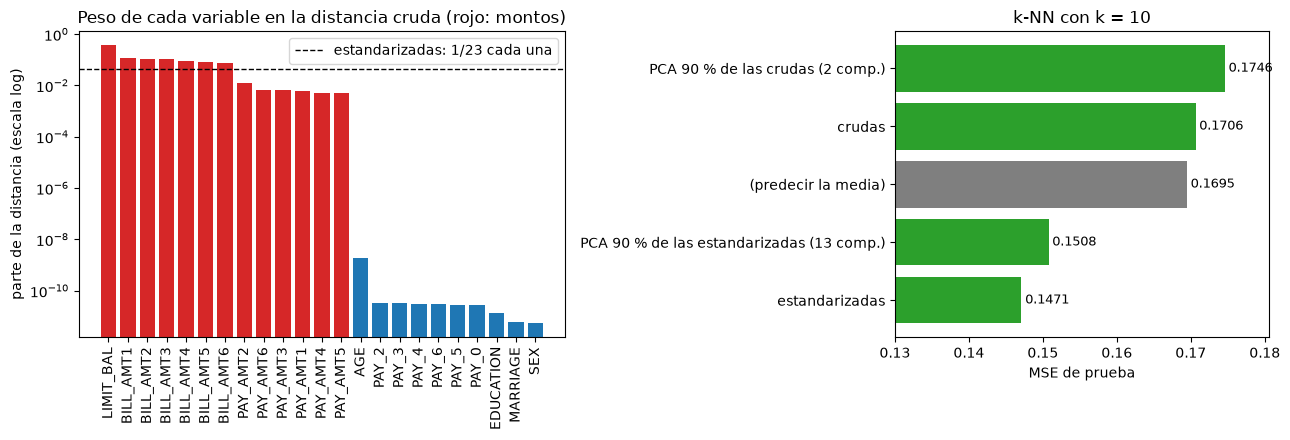

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})
colores = ["tab:red" if grupo(v) == "montos" else "tab:blue" for v in peso.index]
ejes[0].bar(peso.index, peso, color=colores)
ejes[0].set_yscale("log")
ejes[0].axhline(1 / len(sd), color="k", ls="--", lw=1, label="estandarizadas: 1/23 cada una")
ejes[0].tick_params(axis="x", rotation=90)
ejes[0].set(ylabel="parte de la distancia (escala log)", title="Peso de cada variable en la distancia cruda (rojo: montos)")
ejes[0].legend()
e = error_knn.sort_values()
ejes[1].barh(e.index, e, color=["tab:gray" if "media" in i else "tab:green" for i in e.index])
ejes[1].set_xlim(0.13, e.max() + 0.006)
ejes[1].set(xlabel="MSE de prueba", title="k-NN con k = 10")
for i, v in enumerate(e):
    ejes[1].text(v + 0.0005, i, f"{v:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig("../figs/parte4_knn_escala.png", dpi=150)
plt.show()

> **Pregunta 4.1.** Reporten el error de prueba. Con las desviaciones estándar de 0.4, ¿qué variables dominan la distancia en escala cruda? ¿Estandarizar siempre ayuda?

**Error de prueba de k-NN con $k = 10$:** 0.1706 con las variables crudas, 0.1471 estandarizadas y 0.1508 con los 13 componentes principales que explican el 90 % de la varianza de las estandarizadas. En escala cruda, k-NN es **peor que predecir siempre la tasa de mora** (0.1695).

**Qué domina la distancia cruda.** La distancia euclidiana al cuadrado es la suma de $(x_{iv} - x_{jv})^2$ sobre las variables, y en promedio cada variable aporta $2\,\text{sd}_v^2$. Entonces el peso de cada variable es proporcional a su varianza. `LIMIT_BAL` (sd ≈ 129 000) se lleva el 37 % de la distancia, los seis `BILL_AMT` cerca del 59 % y los `PAY_AMT` el resto: los montos se llevan prácticamente el 100 %. Los meses de atraso `PAY_0`–`PAY_6`, que son las variables que más predicen la mora (Parte 2), aportan juntos $2 \times 10^{-10}$ de la distancia: en crudo k-NN no los ve. Busca clientes con límite y facturas parecidas, aunque uno vaya al día y el otro lleve meses sin pagar. El PCA de las crudas lo confirma: 2 componentes ya explican el 90 % de la varianza (el primero, 61 %, es casi solo `LIMIT_BAL` y `BILL_AMT`), y k-NN sobre ellos es el peor de todos (0.1746).

**¿Estandarizar siempre ayuda?** No. Aquí ayuda porque la variable informativa (`PAY_0`) tenía una desviación estándar diminuta. Pero estandarizar no le da a cada variable el peso que merece para predecir, sino **el mismo peso a todas**: `SEX` o `MARRIAGE` cuentan lo mismo que `PAY_0`, y los seis `BILL_AMT`, que se mueven juntos, votan seis veces. Si las variables con desviación grande fueran las que predicen y las chicas fueran ruido, estandarizar empeoraría a k-NN. Lo mismo pasa con el PCA: quedarse con el 90 % de la varianza (0.1508) es peor que usar todas las estandarizadas (0.1471), porque el 10 % que se tira tenía información sobre $y$. Varianza no es lo mismo que relevancia. Escoger la escala es escoger el kernel, y ninguna escala automática garantiza el bueno.

## 4.2 · Los 10 vecinos de una consulta en las dos escalas

Se usan los modelos de 4.1. Para las tres consultas de 2.1 se cuenta cuántos de los 10 vecinos comparten las dos escalas; el detalle se muestra para la consulta de $N_{\text{ef}}$ mediano.

In [6]:
vecinos = {}
for nombre, c in consultas.items():
    assert X_test.index[c["posicion"]] == c["indice"]
    crudo = knn["crudas"].kneighbors(Xc_test.iloc[[c["posicion"]]], return_distance=False)[0]
    est = knn["estandarizadas"].kneighbors(X_test.iloc[[c["posicion"]]], return_distance=False)[0]
    vecinos[nombre] = (crudo, est)
pd.DataFrame({nombre: {"vecinos en común (de 10)": len(set(a) & set(b)),
                       "mora entre vecinos crudos": y_train[a].mean(), "mora entre vecinos estandarizados": y_train[b].mean(),
                       "y real": y_test[consultas[nombre]["posicion"]]}
              for nombre, (a, b) in vecinos.items()}).T

,vecinos en común (de 10),mora entre vecinos crudos,mora entre vecinos estandarizados,y real
nef_mediano,0.0,0.1,0.0,0.0
nef_minimo,2.0,0.9,0.8,0.0
mayor_desacuerdo,1.0,0.2,0.5,1.0


In [7]:
cols = ["LIMIT_BAL", "AGE", "PAY_0", "PAY_2", "BILL_AMT1", "PAY_AMT1"]
c = consultas["nef_mediano"]
crudo, est = vecinos["nef_mediano"]
def ficha(pos, escala):
    t = Xc_train.iloc[pos][cols].assign(default=y_train[pos].astype(int), escala=escala)
    return t
detalle = pd.concat([Xc_test.iloc[[c["posicion"]]][cols].assign(default=int(y_test[c["posicion"]]), escala="consulta"),
                     ficha(crudo, "vecino crudo"), ficha(est, "vecino estandarizado")])
detalle["en ambas"] = detalle.index.isin(set(X_train.index[crudo]) & set(X_train.index[est]))
detalle

,LIMIT_BAL,AGE,PAY_0,PAY_2,BILL_AMT1,PAY_AMT1,default,escala,en ambas
591,160000,34,0,0,83255,4000,0,consulta,False
24740,160000,33,0,0,82535,4000,1,vecino crudo,False
27096,160000,33,0,0,78859,4000,0,vecino crudo,False
716,160000,27,0,0,80964,4000,0,vecino crudo,False
29283,160000,25,0,0,85748,4000,0,vecino crudo,False
21442,160000,25,0,0,83005,3900,0,vecino crudo,False
23083,150000,28,0,0,82559,3500,0,vecino crudo,False
8328,170000,48,0,0,83074,4100,0,vecino crudo,False
20908,150000,49,0,0,86035,3090,0,vecino crudo,False
18660,150000,25,0,0,78823,3000,0,vecino crudo,False


> **Pregunta 4.2.** Para una de sus consultas de la Parte 2, comparen los 10 vecinos en escala cruda y estandarizada. ¿Cuántos comparten?

En la consulta de $N_{\text{ef}}$ mediano (índice 591) **no comparten ninguno** de los 10. En las otras dos consultas comparten 2 y 1.

La tabla muestra por qué. En crudo, los vecinos de 591 son clientes con `LIMIT_BAL` entre 150 000 y 170 000 y `BILL_AMT1` a menos de unos 5 000 de su 83 255, pero con edades de 25 a 49 años: la distancia solo mira los montos. En estandarizado, el límite de crédito de los vecinos va de 100 000 a 220 000 (en unidades de desviación estándar esa diferencia es chica), pero todos tienen entre 29 y 36 años, igual que la consulta (34). Cambiar la escala cambia quién es "parecido".

Y eso cambia la predicción: en 591 la mora de los vecinos es 0.1 en crudo y 0.0 en estandarizado. En la consulta de mayor desacuerdo es 0.2 contra 0.5 (y ese cliente sí cayó en mora). Es el mismo modelo y el mismo $k$, pero con otro kernel.

## 4.3 · El mismo árbol en crudo y estandarizado

Se ajusta `DecisionTreeRegressor(random_state=0)` con la profundidad de `hiperparametros.json` y, para buscar dónde aparecen diferencias, también con profundidad 10 y sin límite. Se compara la estructura (variable de cada nodo, umbrales llevados a escala cruda con $u_{\text{crudo}} = \mu + \sigma\,u_{\text{est}}$, hojas de entrenamiento) y las predicciones de prueba.

In [8]:
media = Xc_train.mean()
filas, arboles = [], {}
for prof in [hp["max_depth"], 10, None]:
    a = DecisionTreeRegressor(max_depth=prof, random_state=0).fit(Xc_train, y_train)
    b = DecisionTreeRegressor(max_depth=prof, random_state=0).fit(X_train, y_train)
    arboles[prof] = (a, b)
    interno = a.tree_.feature >= 0
    v = a.tree_.feature[interno]
    misma = a.tree_.node_count == b.tree_.node_count and (a.tree_.feature == b.tree_.feature).all()
    umbral = b.tree_.threshold[interno] * sd.iloc[v].to_numpy() + media.iloc[v].to_numpy()
    pa, pb = a.predict(Xc_test), b.predict(X_test)
    filas.append({"profundidad": "sin límite" if prof is None else prof, "hojas": a.get_n_leaves(),
                  "misma variable en cada nodo": misma,
                  "máx. |dif. de umbral| / sd": np.max(np.abs(a.tree_.threshold[interno] - umbral) / sd.iloc[v].to_numpy()),
                  "filas de entr. en otra hoja": int((a.apply(Xc_train) != b.apply(X_train)).sum()),
                  "pred. de prueba distintas": int((pa != pb).sum()), "máx. |dif. de pred.|": np.abs(pa - pb).max()})
pd.DataFrame(filas).set_index("profundidad")

,hojas,misma variable en cada nodo,máx. |dif. de umbral| / sd,filas de entr. en otra hoja,pred. de prueba distintas,máx. |dif. de pred.|
profundidad,,,,,,
4,16,True,2.957002e-08,0,0,0.000000
10,393,True,3.263970e-07,0,1,0.813333
sin límite,3772,True,3.263970e-07,0,8,1.000000


In [9]:
# ¿Dónde se separan los caminos? Para cada fila de prueba con predicción distinta, el último nodo común
def separacion(a, b, i):
    ca = a.decision_path(Xc_test.iloc[[i]]).indices
    cb = b.decision_path(X_test.iloc[[i]]).indices
    nodo = [u for u, w in zip(ca, cb) if u == w][-1]
    v = a.tree_.feature[nodo]
    en_nodo = a.decision_path(Xc_train)[:, nodo].toarray().ravel() == 1
    valores = Xc_train.iloc[en_nodo, v]
    u = a.tree_.threshold[nodo]
    return {"fila de prueba": i, "nodo": nodo, "variable": X_train.columns[v],
            "valor crudo": Xc_test.iloc[i, v], "umbral crudo": u,
            "entr. justo abajo": valores[valores <= u].max(), "entr. justo arriba": valores[valores > u].min(),
            "valor est. (float32)": f"{np.float32(X_test.iloc[i, v]):.9f}", "umbral est.": f"{b.tree_.threshold[nodo]:.9f}",
            "izquierda en crudo": Xc_test.iloc[i, v] <= u, "izquierda en est.": np.float32(X_test.iloc[i, v]) <= b.tree_.threshold[nodo]}

casos = pd.DataFrame([separacion(*arboles[prof], i) | {"profundidad": "sin límite" if prof is None else prof}
                      for prof in [10, None]
                      for i in np.flatnonzero(arboles[prof][0].predict(Xc_test) != arboles[prof][1].predict(X_test))])
print("¿En todas el valor crudo es exactamente el umbral?", (casos["valor crudo"] == casos["umbral crudo"]).all())
casos.set_index(["profundidad", "fila de prueba"])

¿En todas el valor crudo es exactamente el umbral? True


nodo   variable  valor crudo  umbral crudo  \
profundidad fila de prueba                                               
10          889              168  LIMIT_BAL       170000      170000.0   
sin límite  496             5885        AGE           24          24.0   
            757              410        AGE           33          33.0   
            768              550  LIMIT_BAL       170000      170000.0   
            889             2618  LIMIT_BAL       170000      170000.0   
            1152            1006   PAY_AMT2         1496        1496.0   
            2052             381  EDUCATION            2           2.0   
            2503            7500        AGE           36          36.0   
            4446            4556        AGE           27          27.0   

                            entr. justo abajo  entr. justo arriba  \
profundidad fila de prueba                                          
10          889                        160000              180000   
sin límite  496                            23                  25   
            757                            32                  34   
            768                        160000              180000   
            889                        160000              180000   
            1152                         1492                1500   
            2052                            1                   3   
            2503                           35                  37   
            4446                           26                  28   

                           valor est. (float32)   umbral est.  \
profundidad fila de prueba                                      
10          889                     0.017524086   0.017524084   
sin límite  496                    -1.246797681  -1.246797740   
            757                    -0.267598033  -0.267598040   
            768                     0.017524086   0.017524084   
            889                     0.017524086   0.017524084   
            1152                   -0.189058512  -0.189058520   
            2052                    0.188973472   0.188973427   
            2503                    0.058801848   0.058801847   
            4446                   -0.920397818  -0.920397848   

                            izquierda en crudo  izquierda en est.  
profundidad fila de prueba                                         
10          889                           True              False  
sin límite  496                           True              False  
            757                           True              False  
            768                           True              False  
            889                           True              False  
            1152                          True              False  
            2052                          True              False  
            2503                          True              False  
            4446                          True              False

> **Pregunta 4.3.** Ajusten el mismo árbol sobre las variables crudas y estandarizadas. En teoría la escala no le importa. ¿Por qué? ¿Da exactamente lo mismo? Si no, expliquen la diferencia.

**Por qué no debería importar.** Un corte $x_v \le u$ solo separa las filas en las que quedan abajo y las que quedan arriba, y el criterio (cuánto baja la suma de cuadrados de $y$) solo depende de qué filas caen de cada lado. Estandarizar, $z = (x - \mu)/\sigma$ con $\sigma > 0$, es una función creciente: no cambia el orden de los valores. Entonces cada corte posible en crudo tiene exactamente un corte en estandarizado que deja las mismas filas de cada lado, con la misma ganancia. El árbol escoge la misma variable y la misma partición, con umbral $u_{\text{est}} = (u - \mu)/\sigma$, y como las hojas tienen las mismas filas, también los mismos promedios.

**Comprobación.** Con la profundidad de la validación cruzada (4) da **exactamente lo mismo**: la misma variable en cada nodo, umbrales equivalentes hasta $3 \times 10^{-8}$ desviaciones estándar, todas las filas de entrenamiento en la misma hoja y las 6 000 predicciones de prueba idénticas. Con profundidad 10 y sin límite la estructura sigue siendo idéntica (ninguna fila de entrenamiento cambia de hoja), pero cambian 1 y 8 predicciones de prueba, con diferencias de hasta 0.81 y 1.0.

**La diferencia es un empate en el umbral más un redondeo.** scikit-learn pone el umbral en el punto medio entre dos valores de entrenamiento consecutivos del nodo. En el nodo 168 (profundidad 10) hay clientes con `LIMIT_BAL` = 160 000 y 180 000, pero ninguno con 170 000, así que el umbral es 170 000. La fila de prueba 889 tiene **exactamente** 170 000:

- en crudo, $170\,000 \le 170\,000$ y se va a la izquierda;
- en estandarizado, scikit-learn convierte $X$ a `float32`. El punto medio de los dos valores estandarizados redondeados da 0.017524084 y el valor de la fila, redondeado, da 0.017524086, dos milmillonésimas por encima. Se va a la derecha y cae en otra hoja.

Los 9 casos son iguales: el valor de prueba es justo el umbral. Pasa porque en Taiwan casi todas las variables son enteras o montos redondos (`LIMIT_BAL` en múltiplos de 10 000, `AGE`, `EDUCATION`), así que un cliente de prueba puede caer justo en medio de dos valores de entrenamiento. En entrenamiento no pasa nunca, porque el punto medio está siempre entre dos valores que sí existen en el nodo. Con árboles más profundos hay más nodos con pocas filas y huecos entre sus valores, y por eso más casos. No son dos modelos distintos: es la misma partición, que solo difiere en qué lado del umbral queda un punto que cae exactamente sobre él.

## 4.4 · k-means en crudo y estandarizado

Para escoger $k$ se barre $k = 2, \dots, 8$ en las dos escalas con la inercia (codo) y la silueta. La silueta se calcula sobre una muestra fija de 5 000 filas de entrenamiento porque con 24 000 es lenta.

In [10]:
muestra = np.random.default_rng(0).choice(len(X_train), 5000, replace=False)
escalas = {"crudas": Xc_train.to_numpy(), "estandarizadas": X_train.to_numpy()}
filas = []
for k in range(2, 9):
    for nombre, X in escalas.items():
        km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
        filas.append({"k": k, "escala": nombre, "inercia": km.inertia_,
                      "silueta": silhouette_score(X[muestra], km.labels_[muestra])})
barrido = pd.DataFrame(filas).pivot(index="k", columns="escala")
barrido["silueta"].round(3)

escala,crudas,estandarizadas
k,,
2,0.552,0.342
3,0.449,0.186
4,0.459,0.166
5,0.418,0.160
6,0.418,0.144
7,0.391,0.144
8,0.382,0.131


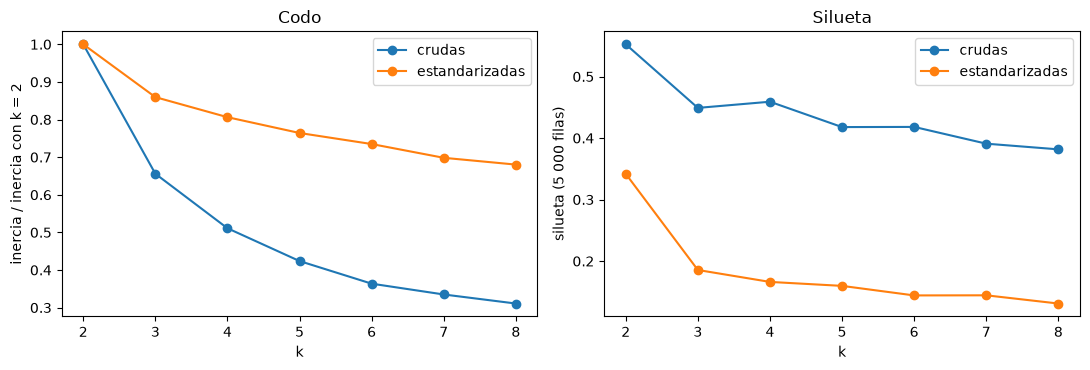

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
for nombre in escalas:
    inercia = barrido["inercia"][nombre]
    ejes[0].plot(inercia.index, inercia / inercia.iloc[0], marker="o", label=nombre)
    ejes[1].plot(barrido.index, barrido["silueta"][nombre], marker="o", label=nombre)
ejes[0].set(xlabel="k", ylabel="inercia / inercia con k = 2", title="Codo")
ejes[1].set(xlabel="k", ylabel="silueta (5 000 filas)", title="Silueta")
for ax in ejes:
    ax.legend()
plt.tight_layout()
plt.savefig("../figs/parte4_kmeans_k.png", dpi=150)
plt.show()

In [12]:
K = 2
grupos = {nombre: KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(X) for nombre, X in escalas.items()}
# k-means numera los grupos al azar: se renumeran para que el grupo 1 sea el de saldos altos en las dos escalas
for nombre, g in grupos.items():
    if Xc_train.BILL_AMT1[g == 0].mean() > Xc_train.BILL_AMT1[g == 1].mean():
        grupos[nombre] = 1 - g
pd.crosstab(pd.Series(grupos["crudas"], name="grupo crudo"), pd.Series(grupos["estandarizadas"], name="grupo estandarizado"), margins=True)

grupo estandarizado,0,1,All
grupo crudo,,,
0,20093,562,20655
1,135,3210,3345
All,20228,3772,24000


In [13]:
# Qué variable separa los grupos: R² = varianza entre grupos / varianza total, en cada variable
def r2(etiquetas):
    medias = Xc_train.groupby(etiquetas).transform("mean")
    return 1 - ((Xc_train - medias) ** 2).sum() / ((Xc_train - Xc_train.mean()) ** 2).sum()
separa = pd.DataFrame({f"R² grupos {n}": r2(g) for n, g in grupos.items()})
separa.sort_values("R² grupos crudas", ascending=False).head(8).round(3)

,R² grupos crudas,R² grupos estandarizadas
BILL_AMT4,0.605,0.618
BILL_AMT2,0.604,0.594
BILL_AMT3,0.602,0.598
BILL_AMT5,0.587,0.610
BILL_AMT1,0.586,0.560
BILL_AMT6,0.557,0.589
LIMIT_BAL,0.127,0.093
PAY_AMT1,0.044,0.050


In [14]:
resumen = {}
for nombre, g in grupos.items():
    t = Xc_train.groupby(g)[["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1", "PAY_0", "AGE"]].mean()
    t.insert(0, "filas", np.bincount(g))
    t["tasa de mora"] = pd.Series(y_train).groupby(g).mean()
    resumen[nombre] = t
pd.concat(resumen, names=["escala", "grupo"]).round(2)

filas  LIMIT_BAL  BILL_AMT1  PAY_AMT1  PAY_0    AGE  \
escala         grupo                                                        
crudas         0      20655  149130.28   28738.46   4266.52  -0.06  35.23   
               1       3345  282588.25  191300.96  14365.79   0.27  36.90   
estandarizadas 0      20228  150676.59   27631.32   4066.33  -0.08  35.22   
               1       3772  259188.14  178835.71  14296.12   0.36  36.77   

                      tasa de mora  
escala         grupo                
crudas         0              0.23  
               1              0.19  
estandarizadas 0              0.22  
               1              0.22

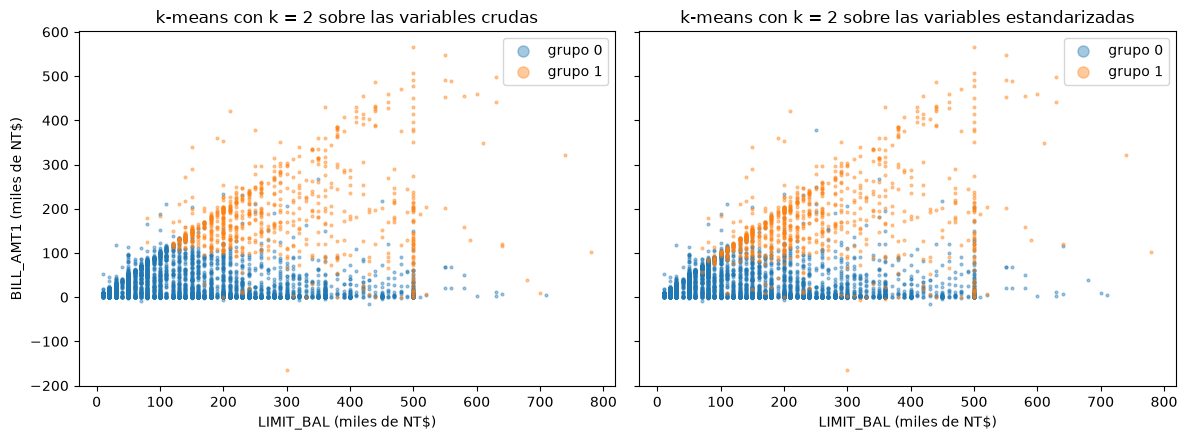

In [15]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
for ax, (nombre, g) in zip(ejes, grupos.items()):
    for j in range(K):
        m = g[muestra] == j
        ax.scatter(Xc_train.LIMIT_BAL.iloc[muestra][m] / 1e3, Xc_train.BILL_AMT1.iloc[muestra][m] / 1e3, s=4, alpha=0.4, label=f"grupo {j}")
    ax.set(title=f"k-means con k = {K} sobre las variables {nombre}", xlabel="LIMIT_BAL (miles de NT$)")
    ax.legend(markerscale=4)
ejes[0].set_ylabel("BILL_AMT1 (miles de NT$)")
plt.tight_layout()
plt.savefig("../figs/parte4_kmeans_grupos.png", dpi=150)
plt.show()

> **Pregunta 4.4.** Hagan k-means (escojan y justifiquen $k$) con variables crudas y estandarizadas. Hagan la tabla cruzada de las dos asignaciones. ¿Qué variable separa los grupos en escala cruda?

**Elección de $k$.** La silueta es máxima en $k = 2$ en las dos escalas (0.55 en crudo y 0.34 en estandarizado) y cae al pasar a 3. El codo no es claro: en crudo la inercia baja mucho hasta $k = 3$ o 4 y en estandarizado baja poco a poco, sin quiebre. Se escoge $k = 2$ en las dos escalas, porque para la tabla cruzada hace falta el mismo $k$. Que la silueta cruda sea más alta no quiere decir que esos grupos sean mejores: la distancia cruda es casi de una sola dimensión (los montos), y en una dimensión es fácil separar.

**Tabla cruzada.** Las dos asignaciones coinciden en el 97 % de los clientes (20 093 + 3 210 de 24 000). En las dos escalas sale un grupo grande de saldos bajos y uno chico de saldos altos (3 345 en crudo y 3 772 en estandarizado). Solo 697 clientes cambian de grupo.

**Qué variable separa los grupos en crudo.** Las facturas `BILL_AMT1`–`BILL_AMT6`: los grupos explican cerca del 60 % de su varianza ($R^2 \approx 0.59$–$0.61$). En promedio, `BILL_AMT1` es de 191 000 en el grupo alto y de 29 000 en el bajo. `LIMIT_BAL`, aunque es la variable con mayor desviación estándar, solo tiene $R^2 = 0.13$. La razón es que los seis `BILL_AMT` se mueven juntos: como bloque son cerca del 59 % de la distancia cruda contra el 37 % de `LIMIT_BAL`, y k-means corta en la dirección de mayor varianza, que es la del primer componente del PCA crudo (facturas y límite).

**Por qué estandarizar casi no cambia el resultado aquí.** Al estandarizar, cada variable pesa 1/23, pero los seis `BILL_AMT` siguen muy correlacionados y forman un bloque de seis votos iguales. Esa sigue siendo la dirección de mayor varianza, y los grupos estandarizados también se separan por las facturas ($R^2 \approx 0.56$–$0.62$). Ninguna de las dos agrupaciones separa la mora (0.23 contra 0.19 en crudo y 0.22 contra 0.22 en estandarizado): k-means no mira $y$, agrupa por el tamaño de la cuenta y no por el riesgo.